<a href="https://colab.research.google.com/github/HamzaEric/caltech101-transfer-learning/blob/main/Notebooks/Finetuning_Convolutional_layers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fine-Tuning

Fine-tuning is the process of *partially unfreezing* a pretrained model so that some of its layers can adapt to the new dataset.  
Instead of keeping the entire convolutional backbone frozen, we’ll allow a few of its deeper layers to learn again, but at a **very small learning rate**.  
This helps the model slightly reshape its internal representations while still retaining most of its pretrained knowledge.

**The Risk: Catastrophic Forgetting**

Fine-tuning must be done carefully.  
If the learning rate is too high, the pretrained weights can be overwritten — causing the model to “forget” the general features it had learned from ImageNet.  
This phenomenon is called **catastrophic forgetting**.

That’s why, during fine-tuning, we use:
- a **small learning rate** (e.g., $1\times10^{-4}$ or lower),
- careful layer selection (usually just the top block),
- and limited epochs.

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import os, json
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from pathlib import Path
import zipfile
import shutil
import random
import torch.nn.functional as F
import time
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,f1_score
from PIL import Image
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [3]:
zip_path = '/content/drive/MyDrive/caltech-101.zip'
extract_path = '/content'


os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print(f"Successfully extracted all files to: {extract_path}")

Successfully extracted all files to: /content


In [4]:
!tar -xzf /content/caltech-101/101_ObjectCategories.tar.gz -C /content/caltech-101/

In [5]:
data_dir = '/content/caltech-101/101_ObjectCategories'

class_names = sorted([
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
])

class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}
idx_to_class = {idx: class_name for idx, class_name in enumerate(class_names)}

print(f"Total Classes Found: {len(class_names)}")
print(f"First 5 classes: {class_names[:5]}")

Total Classes Found: 102
First 5 classes: ['BACKGROUND_Google', 'Faces', 'Faces_easy', 'Leopards', 'Motorbikes']


In [6]:
source_dir = Path('/content/caltech-101/101_ObjectCategories')
output_dir = Path('/content/caltech-splits')

# Split ratios
train_ratio = 0.70
val_ratio = 0.15


random.seed(42)  # For reproducible splits

for class_folder in source_dir.iterdir():
    if class_folder.is_dir():
        class_name = class_folder.name

        # Get all valid image files
        images = [f for f in class_folder.iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
        random.shuffle(images)

        n_total = len(images)
        n_train = int(n_total * train_ratio)
        n_val = int(n_total * val_ratio)

        train_imgs = images[:n_train]
        val_imgs = images[n_train:n_train + n_val]
        test_imgs = images[n_train + n_val:]

        # Create destination folders
        for split_name, split_imgs in [('train', train_imgs), ('val', val_imgs), ('test', test_imgs)]:
            split_class_dir = output_dir / split_name / class_name
            split_class_dir.mkdir(parents=True, exist_ok=True)

            for img_path in split_imgs:
                shutil.copy(img_path, split_class_dir / img_path.name)

print(f"Dataset successfully split and saved to: {output_dir}")

Dataset successfully split and saved to: /content/caltech-splits


In [11]:
DATA_ROOT = Path("/content/caltech-splits")
CKPT_DIR  = Path("/content/drive/MyDrive/checkpoints")
FT_LOAD_PATH = CKPT_DIR / "resnet18_feature_extraction.pth"
MAP_PATH      = CKPT_DIR / "class_to_idx.pth"

assert DATA_ROOT.exists(), f"Dataset not found at {DATA_ROOT}"
assert FT_LOAD_PATH.exists(), f"Checkpoint not found at {FT_LOAD_PATH} (run NB01 saves first)"
assert MAP_PATH.exists(), f"class_to_idx mapping not found at {MAP_PATH}"


class_to_idx = torch.load(MAP_PATH, weights_only=False)
idx_to_class = {v: k for k, v in class_to_idx.items()}
class_names = [idx_to_class[i] for i in range(len(idx_to_class))]
num_classes = len(class_names)
print(f"[info] Classes ({num_classes}): {class_names}")

# Transforms (ImageNet-compatible)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
transform = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Datasets & DataLoaders
train_ds = datasets.ImageFolder(DATA_ROOT / "train", transform=transform)
val_ds   = datasets.ImageFolder(DATA_ROOT / "val",   transform=transform)
test_ds  = datasets.ImageFolder(DATA_ROOT / "test",  transform=transform)

from torch.utils.data import DataLoader
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=0)

print(f"[info] Dataset sizes → train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}")



[info] Classes (102): ['BACKGROUND_Google', 'Faces', 'Faces_easy', 'Leopards', 'Motorbikes', 'accordion', 'airplanes', 'anchor', 'ant', 'barrel', 'bass', 'beaver', 'binocular', 'bonsai', 'brain', 'brontosaurus', 'buddha', 'butterfly', 'camera', 'cannon', 'car_side', 'ceiling_fan', 'cellphone', 'chair', 'chandelier', 'cougar_body', 'cougar_face', 'crab', 'crayfish', 'crocodile', 'crocodile_head', 'cup', 'dalmatian', 'dollar_bill', 'dolphin', 'dragonfly', 'electric_guitar', 'elephant', 'emu', 'euphonium', 'ewer', 'ferry', 'flamingo', 'flamingo_head', 'garfield', 'gerenuk', 'gramophone', 'grand_piano', 'hawksbill', 'headphone', 'hedgehog', 'helicopter', 'ibis', 'inline_skate', 'joshua_tree', 'kangaroo', 'ketch', 'lamp', 'laptop', 'llama', 'lobster', 'lotus', 'mandolin', 'mayfly', 'menorah', 'metronome', 'minaret', 'nautilus', 'octopus', 'okapi', 'pagoda', 'panda', 'pigeon', 'pizza', 'platypus', 'pyramid', 'revolver', 'rhino', 'rooster', 'saxophone', 'schooner', 'scissors', 'scorpion', 'se


**ResNet-18 Architecture Overview**

| Stage | Name | Typical Output Size | Description | Trainable Status |
|:------:|:------|:------------------:|:-------------|:----------------|
| 1 | `conv1` + `bn1` + `relu` + `maxpool` | 64×56×56 | Initial convolutional stem extracting low-level edges and textures | ❌ Frozen |
| 2 | `layer1` | 64×56×56 | First residual block — still low-level spatial features | ❌ Frozen |
| 3 | `layer2` | 128×28×28 | Mid-level features — shapes, textures, and contours | ❌ Frozen |
| 4 | `layer3` | 256×14×14 | Higher-level patterns and object parts | ❌ Frozen |
| 5 | `layer4` | 512×7×7 | Deepest convolutional block — object-level abstractions | ✅ To be Unfrozen |
| 6 | `avgpool` + `fc` | 512→`num_classes` | Global pooling + final classifier | ✅ Unfrozen |

In [13]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_classes)

state = torch.load(FT_LOAD_PATH, weights_only=False, map_location="cpu")
model.load_state_dict(state, strict=True)


for p in model.parameters():
    p.requires_grad = False

for p in model.layer4.parameters():
    p.requires_grad = True
for p in model.fc.parameters():
    p.requires_grad = True

model = model.to(device)
model.eval()

print("[info] Loaded NB02 checkpoint and set trainable layers: layer4 + fc")

[info] Loaded NB02 checkpoint and set trainable layers: layer4 + fc


In [14]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

**Print a compact summary of trainable vs frozen parameters**

In [15]:
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params    = total_params - trainable_params

trainable_names = [n for n, p in model.named_parameters() if p.requires_grad]

print(f"[summary] Total parameters:     {total_params:,}")
print(f"[summary] Trainable parameters: {trainable_params:,}")
print(f"[summary] Frozen parameters:    {frozen_params:,}")
print("[summary] Trainable tensors:")
for n in trainable_names:
    print("  -", n)

assert all(n.startswith("layer4.") or n.startswith("fc.") for n in trainable_names), \
    "Unexpected trainable layers detected (only layer4 and fc should be trainable)."

print("[check] Trainability looks correct (only layer4 + fc).")

[summary] Total parameters:     11,228,838
[summary] Trainable parameters: 8,446,054
[summary] Frozen parameters:    2,782,784
[summary] Trainable tensors:
  - layer4.0.conv1.weight
  - layer4.0.bn1.weight
  - layer4.0.bn1.bias
  - layer4.0.conv2.weight
  - layer4.0.bn2.weight
  - layer4.0.bn2.bias
  - layer4.0.downsample.0.weight
  - layer4.0.downsample.1.weight
  - layer4.0.downsample.1.bias
  - layer4.1.conv1.weight
  - layer4.1.bn1.weight
  - layer4.1.bn1.bias
  - layer4.1.conv2.weight
  - layer4.1.bn2.weight
  - layer4.1.bn2.bias
  - fc.weight
  - fc.bias
[check] Trainability looks correct (only layer4 + fc).


### **Optimizer, Learning Rate, and Scheduler**

When we fine-tune a pretrained model, our goal is to **adapt** higher-level features without destroying the knowledge learned during pretraining.  
To achieve this, we use **small learning rates** for the unfrozen pretrained layers so that weight updates are **gentle** and do not cause catastrophic forgetting.

A practical recipe is to use **differential learning rates**:
- A **lower LR** for the unfrozen pretrained layers (here, `layer4`, e.g., $1\times 10^{-4}$).  
- A **slightly higher LR** for the new classifier head (e.g., $1\times 10^{-3}$), since it was not pretrained and can move faster.

We keep the same **criterion** as before: `nn.CrossEntropyLoss()` for multi-class classification.

Optionally, we add a simple scheduler such as `StepLR` to **decay the learning rate** after a couple of epochs. This helps stabilize training and can yield a small boost in generalization.

> Intuition: with a smaller LR on `layer4`, we “nudge” the deepest features to better fit our dataset, while the classifier head adjusts more quickly to those adapted features.


**Set up criterion, differential LRs, and optional scheduler**

In [16]:
criterion = nn.CrossEntropyLoss()

param_groups = [
    {"params": model.layer4.parameters(), "lr": 1e-4, "weight_decay": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3, "weight_decay": 1e-4},
]

optimizer = optim.Adam(param_groups)

use_scheduler = True
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.5) if use_scheduler else None

# print current learning rates per group
def get_lrs(optim_obj):
    return [group["lr"] for group in optim_obj.param_groups]

print("[ok] Optimizer set with differential LRs.")
print("     LRs per group (layer4, fc):", get_lrs(optimizer))

[ok] Optimizer set with differential LRs.
     LRs per group (layer4, fc): [0.0001, 0.001]


### **Fine-Tuning Training Loop**

Because we are updating some pretrained layers (with a **small learning rate**), convergence may be **slightly slower initially** than head-only training, but it can settle at a **better plateau** if our dataset benefits from representation adaptation.

We will:
- Train for **3–4 epochs on CPU** (short, controlled run).  
- Log `train_loss`, `val_loss`, and `val_acc` per epoch.  
- **Visualize** the curves and, if available, **compare** with NB02’s feature-extraction history.

We keep `torch.no_grad()` for validation, and we step the scheduler (if used) **after** each epoch.


In [17]:
def ft_train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    total = 0

    for xb, yb in dataloader:
        xb, yb = xb.to(device), yb.to(device)

        # Forward
        logits = model(xb)
        loss = criterion(logits, yb)

        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Accumulate
        bs = xb.size(0)
        running_loss += loss.item() * bs
        total += bs

    return running_loss / max(total, 1)


@torch.no_grad()
def ft_evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    total = 0
    correct = 0

    for xb, yb in dataloader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)

        bs = xb.size(0)
        running_loss += loss.item() * bs
        total += bs

        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()

    return running_loss / max(total, 1), correct / max(total, 1)


**Run fine-tuning**

In [18]:
num_epochs_ft = 5
ft_history = {"train_loss": [], "val_loss": [], "val_acc": []}

print(f"[start] Fine-tuning layer4 + head for {num_epochs_ft} epochs...")
t_start = time.time()

for epoch in range(1, num_epochs_ft + 1):
    t0 = time.time()

    tr_loss = ft_train_one_epoch(model, train_loader, optimizer, criterion, device)
    va_loss, va_acc = ft_evaluate(model, val_loader, criterion, device)

    if scheduler is not None:
        scheduler.step()

    ft_history["train_loss"].append(tr_loss)
    ft_history["val_loss"].append(va_loss)
    ft_history["val_acc"].append(va_acc)

    dt = time.time() - t0
    print(f"Epoch {epoch:02d} | "
          f"train_loss={tr_loss:.4f} | "
          f"val_loss={va_loss:.4f} | "
          f"val_acc={va_acc:.3f} | "
          f"epoch_time={dt:.1f}s | LRs={ [g['lr'] for g in optimizer.param_groups] }")

print(f"[done] Finished fine-tuning in {time.time() - t_start:.1f}s")


[start] Fine-tuning layer4 + head for 5 epochs...
Epoch 01 | train_loss=0.3903 | val_loss=0.3024 | val_acc=0.913 | epoch_time=251.9s | LRs=[0.0001, 0.001]
Epoch 02 | train_loss=0.0689 | val_loss=0.2638 | val_acc=0.928 | epoch_time=245.9s | LRs=[5e-05, 0.0005]
Epoch 03 | train_loss=0.0238 | val_loss=0.2280 | val_acc=0.930 | epoch_time=265.4s | LRs=[5e-05, 0.0005]
Epoch 04 | train_loss=0.0108 | val_loss=0.2202 | val_acc=0.937 | epoch_time=251.5s | LRs=[2.5e-05, 0.00025]
Epoch 05 | train_loss=0.0075 | val_loss=0.2227 | val_acc=0.931 | epoch_time=249.4s | LRs=[2.5e-05, 0.00025]
[done] Finished fine-tuning in 1264.0s


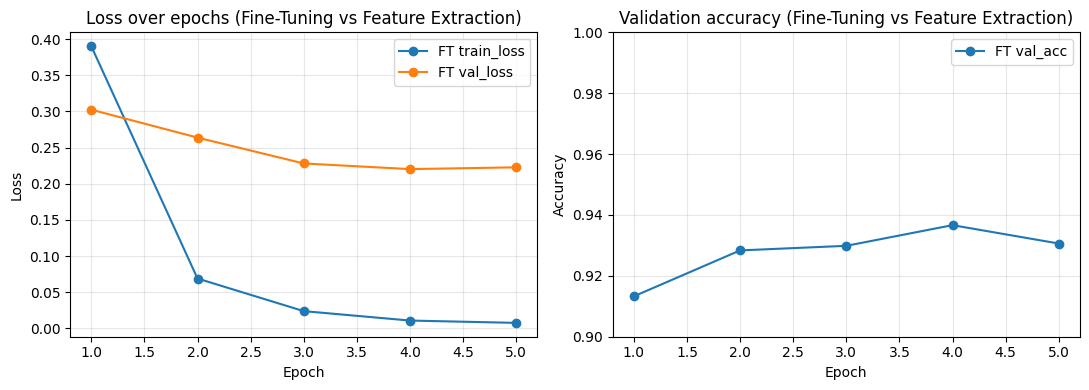

In [19]:
fe_logs_path = Path("./checkpoints/training_logs_feature_extraction.json")
fe_logs = None
if fe_logs_path.exists():
    with open(fe_logs_path, "r") as f:
        fe_logs = json.load(f)

epochs_ft = range(1, len(ft_history["train_loss"]) + 1)

plt.figure(figsize=(11, 4))

# Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_ft, ft_history["train_loss"], marker="o", label="FT train_loss")
plt.plot(epochs_ft, ft_history["val_loss"], marker="o", label="FT val_loss")
if fe_logs is not None:
    e_fe = range(1, len(fe_logs["train_loss"]) + 1)
    plt.plot(e_fe, fe_logs["train_loss"], "--", label="FE train_loss")
    plt.plot(e_fe, fe_logs["val_loss"], "--", label="FE val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over epochs (Fine-Tuning vs Feature Extraction)")
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_ft, ft_history["val_acc"], marker="o", label="FT val_acc")
if fe_logs is not None:
    e_fe = range(1, len(fe_logs["val_acc"]) + 1)
    plt.plot(e_fe, fe_logs["val_acc"], "--", label="FE val_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation accuracy (Fine-Tuning vs Feature Extraction)")
plt.ylim(0.9, 1)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### **6. Evaluating and Comparing Results**

- **Overall accuracy** on the test set.  
- **Per-class precision, recall, and F1**, to see which categories improved.  
- **Confusion matrices (side-by-side)** for FE vs Fine-Tuning (FT), to visualize where confusions decreased or shifted.

In [23]:
# Current model
model.eval()

y_true, y_pred_ft = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        logits = model(xb.to(device))
        preds = torch.argmax(torch.softmax(logits, dim=1), dim=1).cpu().numpy()
        y_pred_ft.extend(preds.tolist())
        y_true.extend(yb.numpy().tolist())

y_true = np.array(y_true)
y_pred_ft = np.array(y_pred_ft)

acc_ft = accuracy_score(y_true, y_pred_ft)
f1_ft_macro = f1_score(y_true, y_pred_ft, average="macro")
print(f"[FT] Test accuracy: {acc_ft:.4f} | Macro F1: {f1_ft_macro:.4f}")

report_ft = classification_report(
    y_true, y_pred_ft, target_names=class_names, digits=3, zero_division=0
)
print("\n[FINE-TUNING] Classification report\n")
print(report_ft)

cm_ft = confusion_matrix(y_true, y_pred_ft, labels=list(range(len(class_names))))


[FT] Test accuracy: 0.9379 | Macro F1: 0.9230

[FINE-TUNING] Classification report

                   precision    recall  f1-score   support

BACKGROUND_Google      0.729     0.873     0.795        71
            Faces      0.954     0.939     0.947        66
       Faces_easy      0.940     0.955     0.947        66
         Leopards      0.938     1.000     0.968        30
       Motorbikes      0.992     1.000     0.996       121
        accordion      1.000     1.000     1.000         9
        airplanes      0.992     0.992     0.992       120
           anchor      1.000     0.714     0.833         7
              ant      0.833     0.714     0.769         7
           barrel      1.000     1.000     1.000         8
             bass      1.000     0.778     0.875         9
           beaver      0.778     0.875     0.824         8
        binocular      1.000     0.833     0.909         6
           bonsai      1.000     1.000     1.000        20
            brain      0.941  

**Load the FE baseline**

In [24]:
fe_ckpt_path = Path("/content/drive/MyDrive/checkpoints/resnet18_feature_extraction.pth")
assert fe_ckpt_path.exists(), "NB02 checkpoint not found: /content/drive/MyDrive/checkpoints/resnet18_feature_extraction.pth"

# Recreate the FE model (frozen backbone, trained head)
model_fe = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
in_features = model_fe.fc.in_features
model_fe.fc = nn.Linear(in_features, len(class_names))

state_fe = torch.load(fe_ckpt_path, weights_only=False, map_location="cpu")
model_fe.load_state_dict(state_fe, strict=True)

for p in model_fe.parameters():
    p.requires_grad = False

model_fe = model_fe.to(device)
model_fe.eval()

y_pred_fe = []
with torch.no_grad():
    for xb, yb in test_loader:
        logits = model_fe(xb.to(device))
        preds = torch.argmax(torch.softmax(logits, dim=1), dim=1).cpu().numpy()
        y_pred_fe.extend(preds.tolist())

y_pred_fe = np.array(y_pred_fe)

acc_fe = accuracy_score(y_true, y_pred_fe)
f1_fe_macro = f1_score(y_true, y_pred_fe, average="macro")
print(f"[FE] Test accuracy: {acc_fe:.4f} | Macro F1: {f1_fe_macro:.4f}")

report_fe = classification_report(
    y_true, y_pred_fe, target_names=class_names, digits=3, zero_division=0
)
print("\n[FEATURE EXTRACTION] Classification report\n")
print(report_fe)

cm_fe = confusion_matrix(y_true, y_pred_fe, labels=list(range(len(class_names))))


[FE] Test accuracy: 0.9318 | Macro F1: 0.9242

[FEATURE EXTRACTION] Classification report

                   precision    recall  f1-score   support

BACKGROUND_Google      0.725     0.817     0.768        71
            Faces      0.906     0.879     0.892        66
       Faces_easy      0.896     0.909     0.902        66
         Leopards      0.968     1.000     0.984        30
       Motorbikes      0.984     1.000     0.992       121
        accordion      0.900     1.000     0.947         9
        airplanes      0.976     1.000     0.988       120
           anchor      0.857     0.857     0.857         7
              ant      0.714     0.714     0.714         7
           barrel      0.875     0.875     0.875         8
             bass      1.000     0.778     0.875         9
           beaver      0.875     0.875     0.875         8
        binocular      1.000     1.000     1.000         6
           bonsai      0.905     0.950     0.927        20
            brain      

In [26]:
compare_df = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1"],
    "Feature Extraction (NB02)": [acc_fe, f1_fe_macro],
    "Fine-Tuning (NB03)": [acc_ft, f1_ft_macro],
})
print(compare_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

  Metric  Feature Extraction (NB02)  Fine-Tuning (NB03)
Accuracy                     0.9318              0.9379
Macro F1                     0.9242              0.9230


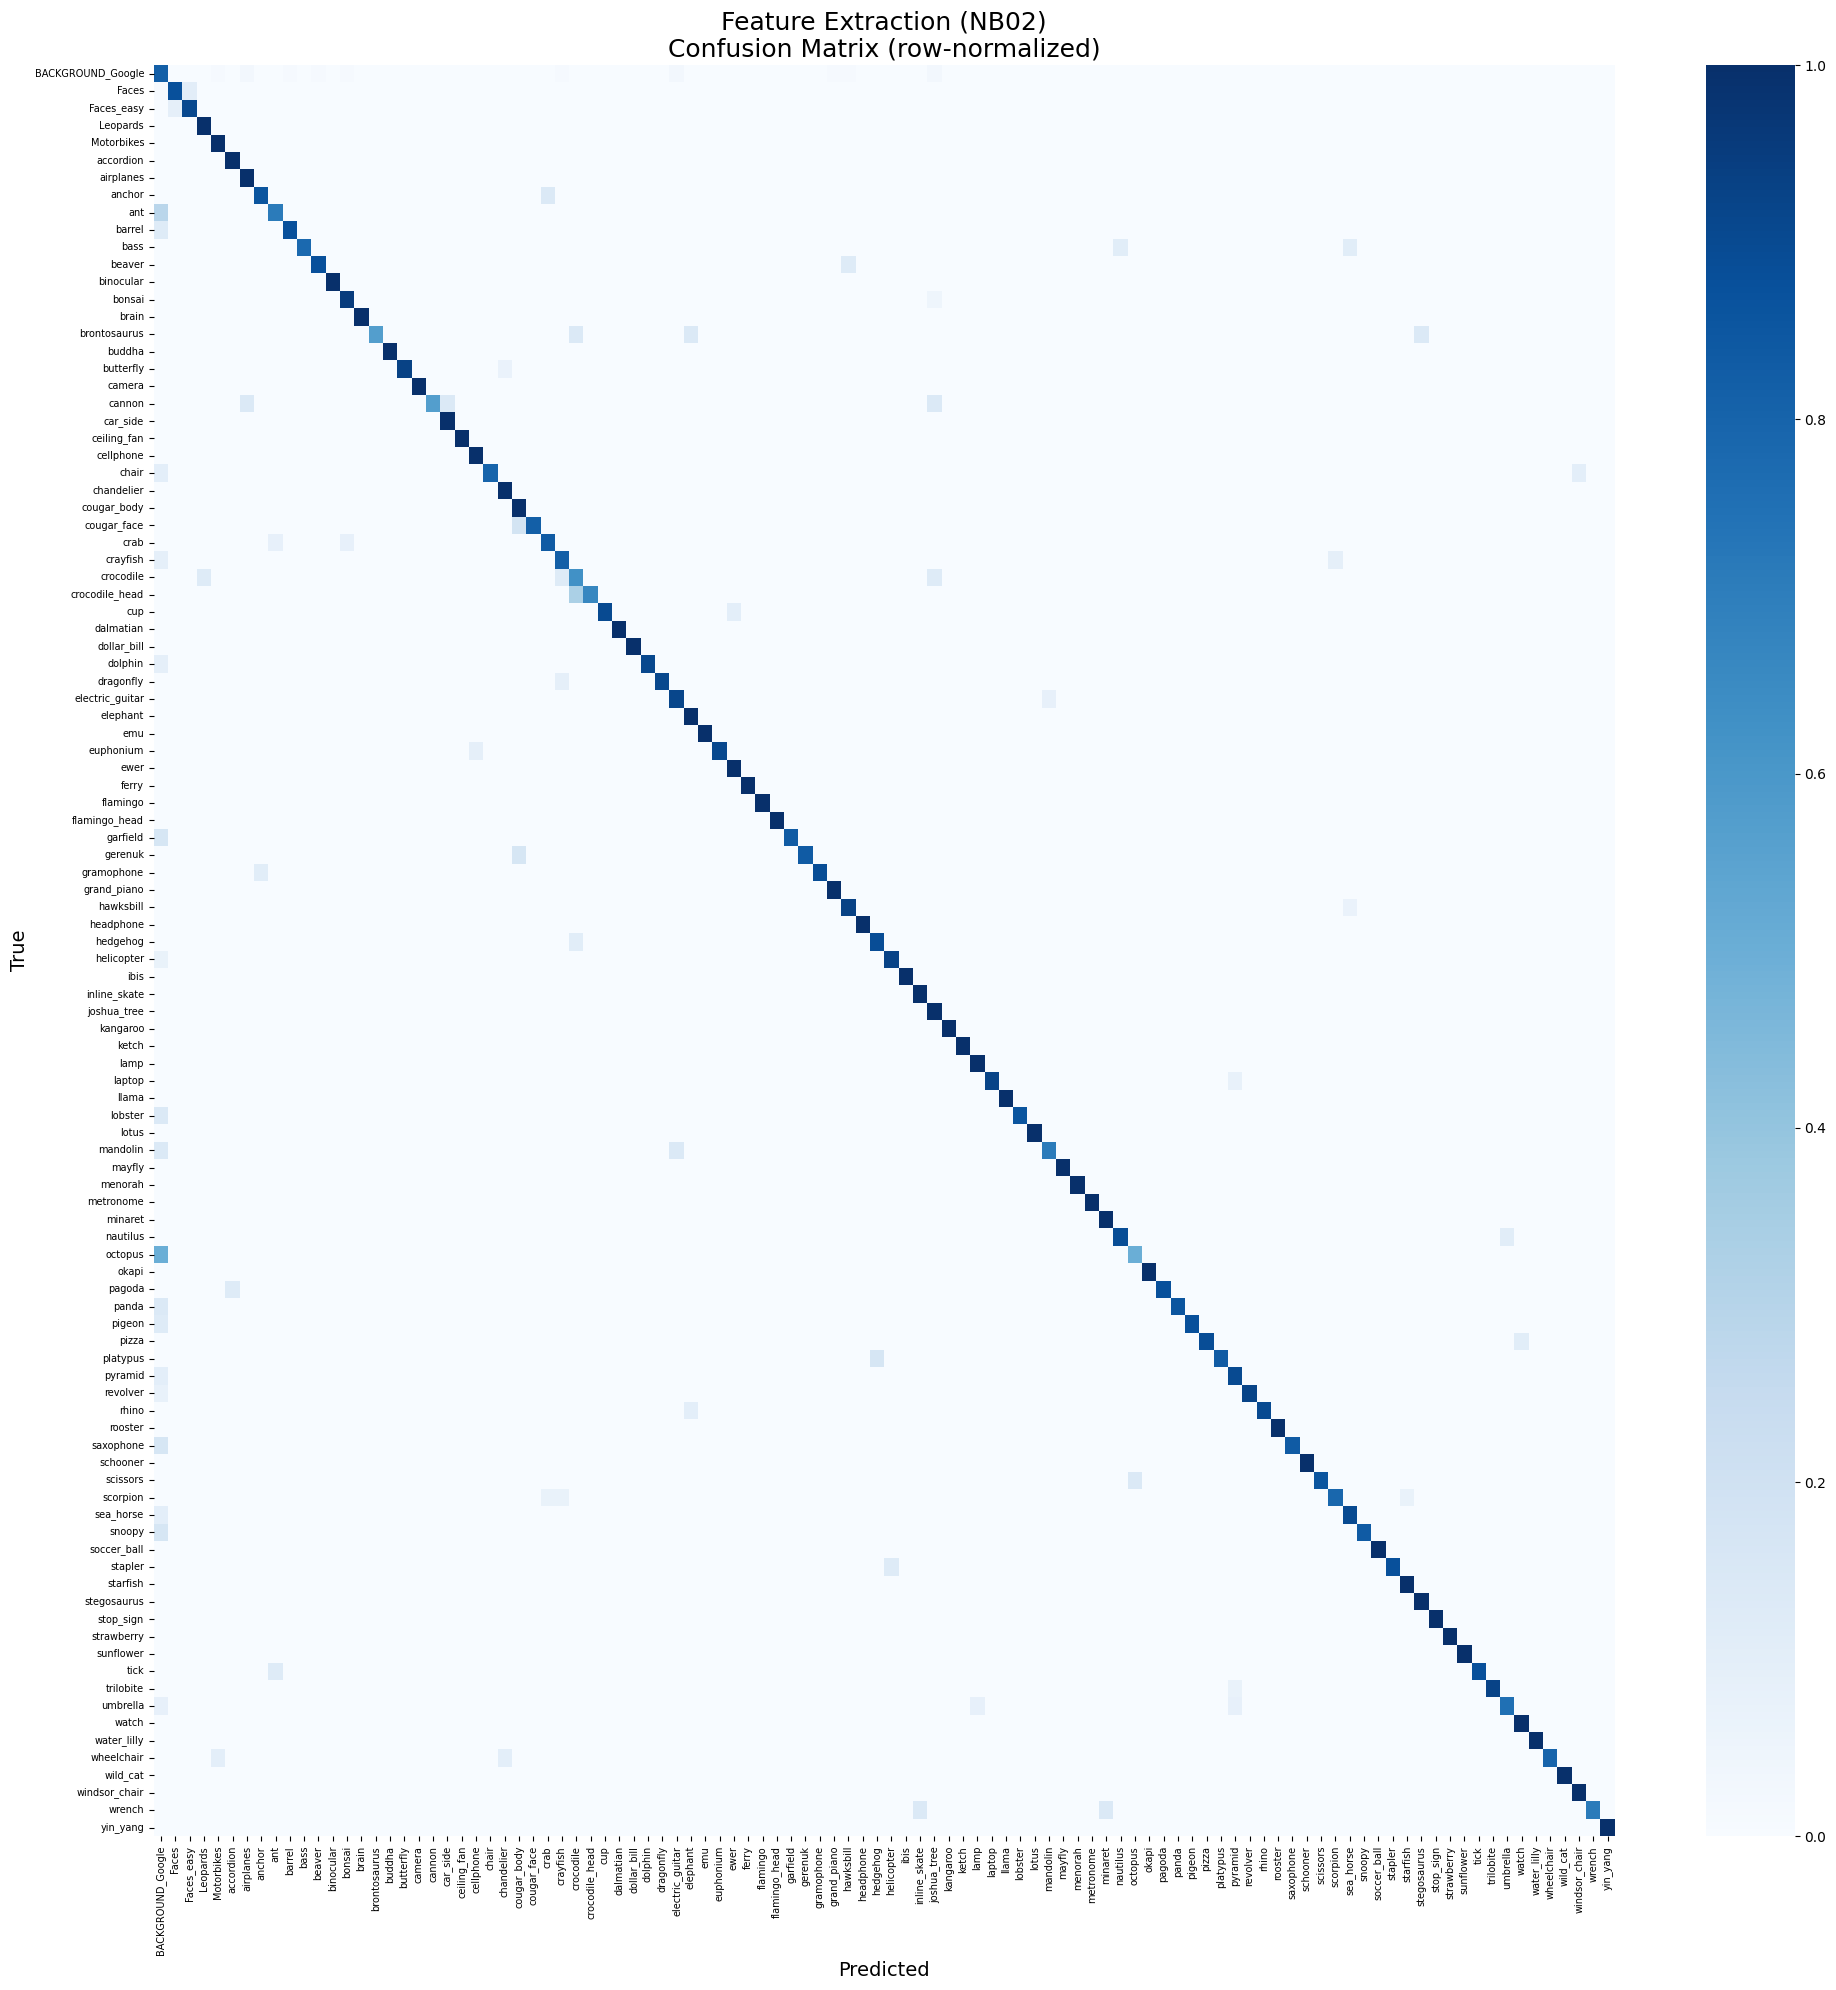

In [29]:
cm_fe_norm = cm_fe.astype(float) / cm_fe.sum(axis=1, keepdims=True).clip(min=1)
cm_ft_norm = cm_ft.astype(float) / cm_ft.sum(axis=1, keepdims=True).clip(min=1)

# ==========================================
# Feature Extraction Confusion Matrix
# ==========================================
plt.figure(figsize=(20, 20)) # Very large figure size
sns.heatmap(cm_fe_norm, cmap="Blues", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names)

plt.title("Feature Extraction (NB02)\nConfusion Matrix (row-normalized)", fontsize=18)
plt.xlabel("Predicted", fontsize=14)
plt.ylabel("True", fontsize=14)

# Rotate x-labels 90 degrees and reduce font size so they don't overlap
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)

plt.tight_layout()
plt.show()

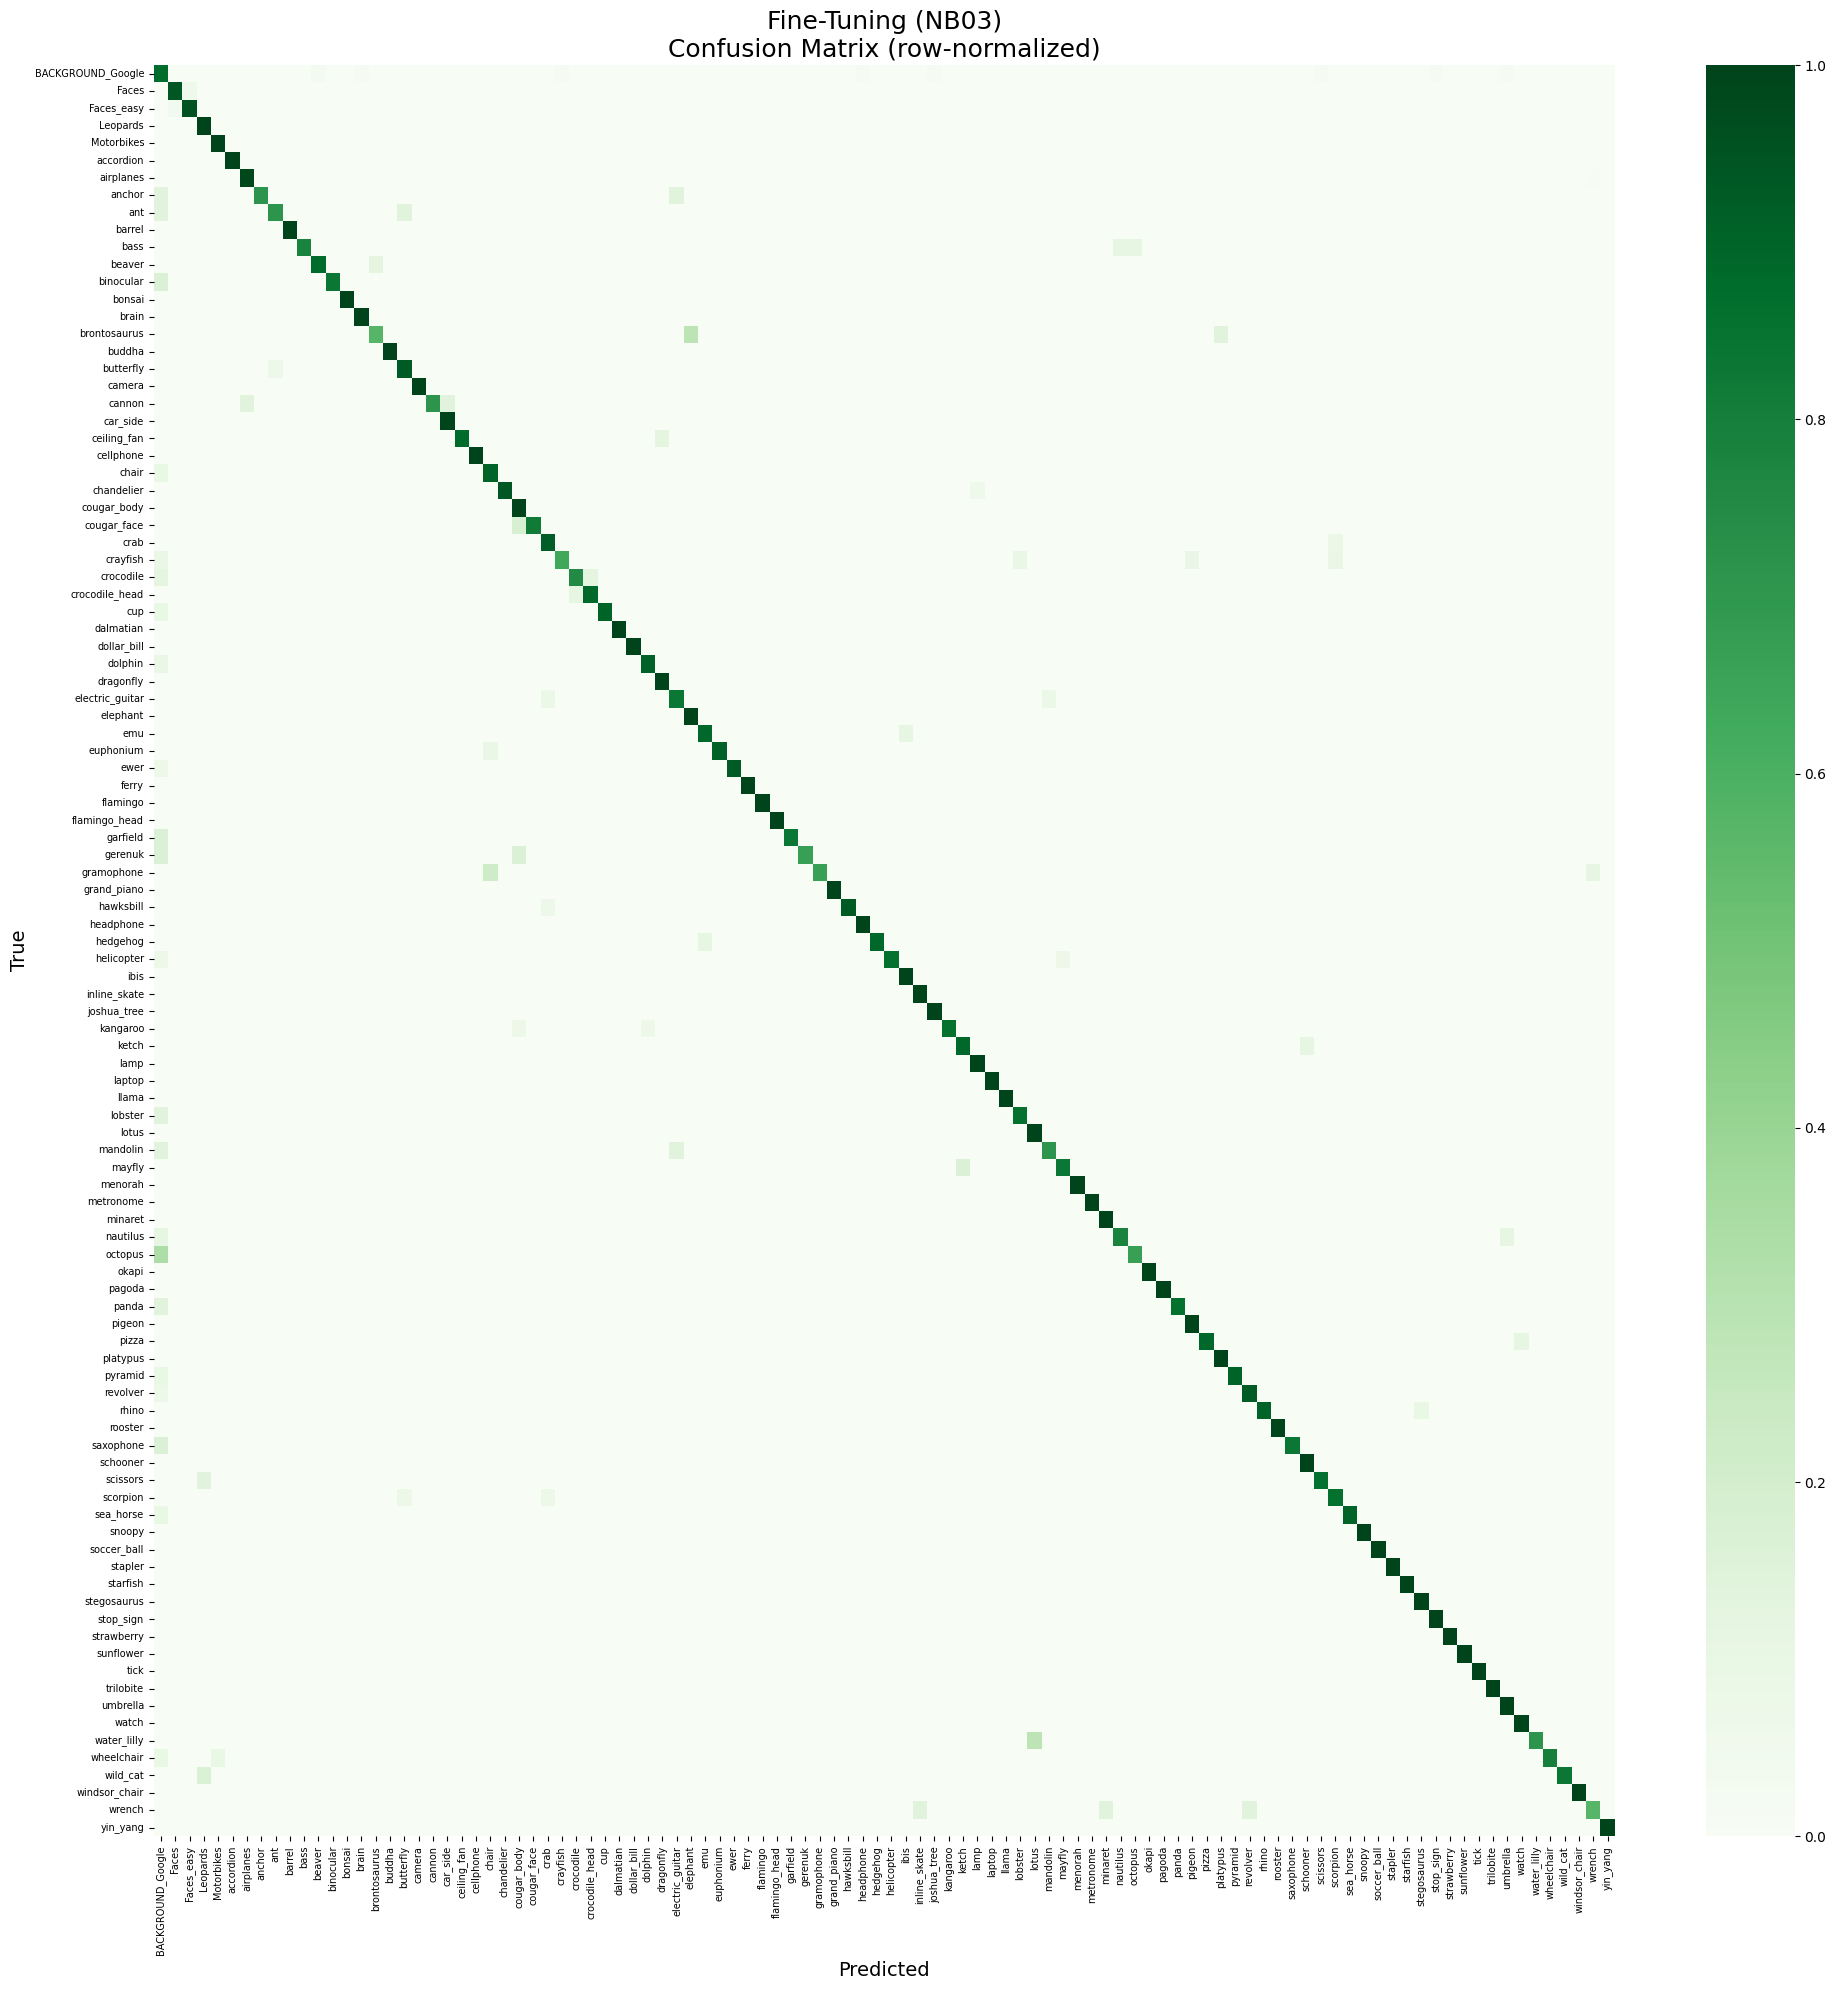

In [30]:
# ==========================================
# Fine-Tuning Confusion Matrix
# ==========================================
plt.figure(figsize=(20, 20)) # Very large figure size
sns.heatmap(cm_ft_norm, cmap="Greens", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names)

plt.title("Fine-Tuning (NB03)\nConfusion Matrix (row-normalized)", fontsize=18)
plt.xlabel("Predicted", fontsize=14)
plt.ylabel("True", fontsize=14)

# Rotate x-labels 90 degrees and reduce font size so they don't overlap
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)

plt.tight_layout()
plt.show()

**Which classes improved the most? (Δ F1 by class)**

In [31]:
from sklearn.metrics import precision_recall_fscore_support

prec_fe, rec_fe, f1_fe, _ = precision_recall_fscore_support(y_true, y_pred_fe, labels=list(range(len(class_names))), zero_division=0)
prec_ft, rec_ft, f1_ft, _ = precision_recall_fscore_support(y_true, y_pred_ft, labels=list(range(len(class_names))), zero_division=0)

delta = f1_ft - f1_fe
per_class = pd.DataFrame({
    "class": class_names,
    "F1_FE": f1_fe,
    "F1_FT": f1_ft,
    "ΔF1": delta
}).sort_values("ΔF1", ascending=False)

print("[per-class ΔF1] Positive values mean fine-tuning improved that class.")
display(per_class)

[per-class ΔF1] Positive values mean fine-tuning improved that class.


,class,F1_FE,F1_FT,ΔF1
29,crocodile,0.555556,0.800000,0.244444
54,joshua_tree,0.814815,0.956522,0.141707
75,pyramid,0.818182,0.947368,0.129187
68,octopus,0.600000,0.727273,0.127273
9,barrel,0.875000,1.000000,0.125000
...,...,...,...,...
38,emu,1.000000,0.888889,-0.111111
46,gramophone,0.941176,0.800000,-0.141176
63,mayfly,1.000000,0.833333,-0.166667
96,water_lilly,1.000000,0.833333,-0.166667


### **Visualizing Feature Adaptation**

To understand **what fine-tuning changed**, we will look inside the network and compare **pre–fine-tuning** (feature extraction, FE) with **post–fine-tuning** (FT) along the last residual stage, `layer4`.

We will visualize two things:

1. **Activation maps** from `layer4` for the *same* image before and after fine-tuning.  
   - If fine-tuning helped, we often see **sharper, more localized activations** over the object of interest or its parts.  
   - If nothing changed, activations may look very similar to the FE case.

2. **Grad-CAM** heatmaps for the **predicted class** before and after fine-tuning.  
   - Grad-CAM highlights the **spatial regions** that contribute most to the model’s decision.  
   - If FT improved performance, Grad-CAM may shift attention from background to **object regions** or attend more strongly to **discriminative parts**.

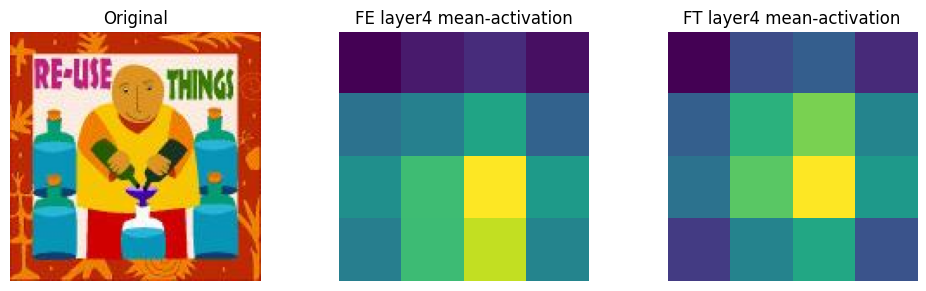

In [32]:
sample_path = val_ds.samples[0][0]  # (path, label)
sample_img = Image.open(sample_path).convert("RGB")

prep = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],[0.229, 0.224, 0.225]),
])

x = prep(sample_img).unsqueeze(0).to(device)

# --- Hook helpers ---
acts_fe, acts_ft = {}, {}

def hook_capturer_acts(store_dict, name):
    def hook(_m, _i, o):
        store_dict[name] = o.detach().cpu()
    return hook

# Register hooks on the LAST conv in layer4 (good Grad-CAM target too)
handle_fe = model_fe.layer4.register_forward_hook(hook_capturer_acts(acts_fe, "layer4"))
handle_ft = model.layer4.register_forward_hook(hook_capturer_acts(acts_ft, "layer4"))

# Forward both models
with torch.no_grad():
    _ = model_fe(x)
    _ = model(x)

# Remove hooks
handle_fe.remove()
handle_ft.remove()

# Reduce channel dimension with mean to a single 2D map for each model
# fe_map = acts_fe["layer4"][0].mean(dim=1).squeeze(0)   # [H, W]
# ft_map = acts_ft["layer4"][0].mean(dim=1).squeeze(0)   # [H, W]

# acts_fe["layer4"]: [B, C, H, W]
fe_map = acts_fe["layer4"].mean(dim=1).squeeze(0)  # [H, W]
ft_map = acts_ft["layer4"].mean(dim=1).squeeze(0)  # [H, W]


# Normalize for display
def norm01(t):
    t = t - t.min()
    return t / (t.max().clamp(min=1e-8))

fe_disp = norm01(fe_map).numpy()
ft_disp = norm01(ft_map).numpy()

# Show original + activation maps
plt.figure(figsize=(10,3))
plt.subplot(1,3,1)
plt.imshow(sample_img)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(fe_disp, cmap="viridis")
plt.title("FE layer4 mean-activation")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(ft_disp, cmap="viridis")
plt.title("FT layer4 mean-activation")
plt.axis("off")

plt.tight_layout()
plt.show()


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:1870: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


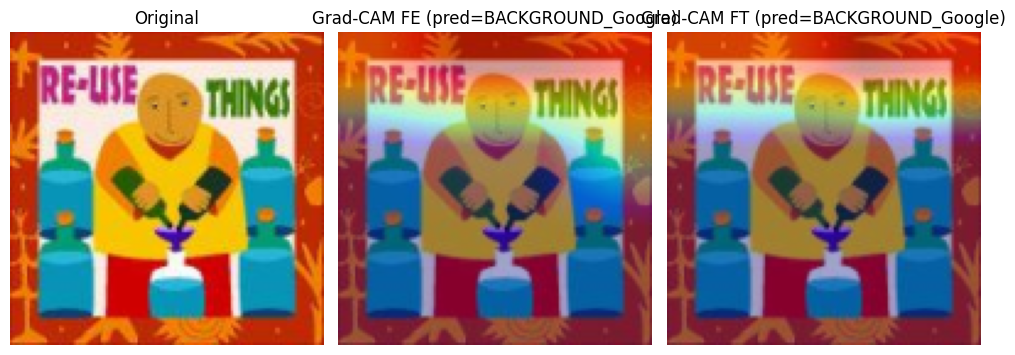

In [33]:
# ==== 1. Enable grads where we need them for Grad-CAM ====

# For feature-extraction model: everything was frozen; we now allow
# layer4 + fc to have grads so we can compute Grad-CAM.
for p in model_fe.parameters():
    p.requires_grad = False
for p in model_fe.layer4.parameters():
    p.requires_grad = True
for p in model_fe.fc.parameters():
    p.requires_grad = True

# For fine-tuned model: layer4 + fc are already trainable, but we
# explicitly ensure that (harmless if already True).
for p in model.layer4.parameters():
    p.requires_grad = True
for p in model.fc.parameters():
    p.requires_grad = True

model_fe.eval()
model.eval()

# ==== 2. Grad-CAM helper ====

def gradcam_for_model(model_ref, x_tensor, target_layer):
    """
    Compute Grad-CAM heatmap [H,W] in 0..1 for the model's predicted class.
    """
    model_ref.eval()
    acts = {}
    grads = {}

    # forward hook: save activations
    def fwd_hook(_m, _i, o):
        acts["a"] = o

    # backward hook: save gradients w.r.t. those activations
    def bwd_hook(_m, grad_in, grad_out):
        grads["g"] = grad_out[0]

    # register hooks
    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_backward_hook(bwd_hook)

    # grad-trackable input
    x_local = x_tensor.clone().detach().requires_grad_(True)

    # forward
    logits = model_ref(x_local)             # [1, num_classes]
    pred_idx = logits.argmax(dim=1).item()  # scalar int

    # backward w.r.t. predicted logit
    score = logits[0, pred_idx]
    model_ref.zero_grad(set_to_none=True)
    score.backward()

    # remove hooks
    h1.remove()
    h2.remove()

    # activations & grads: [C,H,W]
    A = acts["a"][0]
    G = grads["g"][0]

    # channel weights = GAP over spatial dims of gradients
    weights = G.mean(dim=(1, 2), keepdim=True)    # [C,1,1]
    cam = (weights * A).sum(dim=0)                # [H,W]

    # ReLU (standard Grad-CAM)
    cam = torch.relu(cam)

    # normalize 0..1
    cam = cam.detach().cpu()
    cam = cam - cam.min()
    cam = cam / cam.max().clamp(min=1e-8)

    return cam.numpy(), pred_idx

# ==== 3. Run Grad-CAM for both models ====

cam_fe, pred_fe = gradcam_for_model(model_fe, x, model_fe.layer4)
cam_ft, pred_ft = gradcam_for_model(model,    x, model.layer4)

# ==== 4. Prepare original (unnormalized) image ====

def unnorm_for_vis(xb):
    mean = np.array([0.485, 0.456, 0.406])[None, None, :]
    std  = np.array([0.229, 0.224, 0.225])[None, None, :]
    img = xb[0].detach().cpu().permute(1, 2, 0).numpy()
    img = (img * std) + mean
    img = np.clip(img, 0, 1)
    return img

base_rgb = unnorm_for_vis(x)  # shape: (H, W, 3)

# ==== 5. Overlay utility (with CAM upsampling) ====

def overlay_cam(img, cam, alpha=0.35, cmap="jet"):
    """
    img: (H, W, 3), cam: (h, w) in [0,1].
    We resize cam to (H, W) before blending.
    """
    H, W = img.shape[:2]

    if cam.shape != (H, W):
        # upsample CAM using bilinear interpolation
        cam_t = torch.from_numpy(cam).float().unsqueeze(0).unsqueeze(0)  # [1,1,h,w]
        cam_t = F.interpolate(cam_t, size=(H, W), mode="bilinear", align_corners=False)
        cam = cam_t.squeeze().cpu().numpy()  # [H,W]

    heat = plt.get_cmap(cmap)(cam)[..., :3]   # RGBA -> RGB
    return (1 - alpha) * img + alpha * heat

ovl_fe = overlay_cam(base_rgb, cam_fe)
ovl_ft = overlay_cam(base_rgb, cam_ft)

# ==== 6. Plot ====

plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(base_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ovl_fe)
plt.title(f"Grad-CAM FE (pred={class_names[pred_fe]})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ovl_ft)
plt.title(f"Grad-CAM FT (pred={class_names[pred_ft]})")
plt.axis("off")

plt.tight_layout()
plt.show()


In [34]:
save_dir = Path("./checkpoints")
save_dir.mkdir(exist_ok=True, parents=True)

ft_ckpt_path = save_dir / "resnet18_finetuned.pth"
torch.save(model.state_dict(), ft_ckpt_path)

history_ft = {
    "train_loss": ft_history["train_loss"],
    "val_loss": ft_history["val_loss"],
    "val_acc": ft_history["val_acc"],
}
with open(save_dir / "training_logs_finetuned.json", "w") as f:
    json.dump(history_ft, f, indent=4)

print(f"[done] Saved fine-tuned model → {ft_ckpt_path}")
print(f"[done] Saved training logs → {save_dir / 'training_logs_finetuned.json'}")

[done] Saved fine-tuned model → checkpoints/resnet18_finetuned.pth
[done] Saved training logs → checkpoints/training_logs_finetuned.json
